# 2. Alignment, dimensional collapse, and loss ablations

**Question:** Does a locality advantage survive objectives that discourage low-rank representations, or is dimensional collapse central to the observed behavior?

Two encoders learn separately from their own temporal observation pairs. No cross-modal targets, state labels, or shared optimizer are used. Compare the original objective with stronger variance, covariance, and covariance-identity penalties. High coordinate variance is not enough: several coordinates can still encode the same direction.

Start with a small development plan. Use new world IDs for confirmation after settings are frozen. Retain all runs, including collapse flags and undefined metrics. A favorable result is not required.

**Storage:** results remain in memory unless `SAVE_RESULTS` is explicitly enabled with a destination. Editor autosave may separately store displayed cell output in the notebook; clear outputs or disable that feature if needed.

In [26]:
from pathlib import Path
import sys
import subprocess
from zipfile import ZipFile

REPO_URL = 'https://github.com/AlexM3020/The-Role-of-Dynamical-Structure-in-Cross-Modal-Representation-Learning.git'
REPO_REF = 'main'  # For a frozen run, choose a commit before starting a fresh runtime.
SOURCE_ARCHIVE = None  # Optional uploaded source ZIP; not needed in Colab with GitHub access.
INSTALL_DEPENDENCIES = False  # Enable only if the runtime lacks compatible dependencies.
cloud = next((p for p in (Path('/content'), Path('/kaggle/working')) if p.exists()), None)
if SOURCE_ARCHIVE is not None:
    if cloud is None:
        raise RuntimeError('Use the local checkout here; source extraction is for cloud runtimes.')
    destination = cloud / 'dynalign_uploaded_source'
    with ZipFile(SOURCE_ARCHIVE) as archive:
        for name in archive.namelist():
            if not (destination / name).resolve().is_relative_to(destination.resolve()):
                raise ValueError('Unsafe archive member')
        archive.extractall(destination)
    candidates = [destination]
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'src/dynalign/revised.py').exists()), None)
if ROOT is None and SOURCE_ARCHIVE is None and cloud is not None:
    destination = cloud / 'dynalign_github'
    if not destination.exists():
        subprocess.check_call(['git', 'clone', '--quiet', REPO_URL, str(destination)])
        subprocess.check_call(['git', '-C', str(destination), 'fetch', '--quiet', 'origin', REPO_REF])
        subprocess.check_call(['git', '-C', str(destination), 'checkout', '--quiet', '--detach', 'FETCH_HEAD'])
    ROOT = destination
if ROOT is None or not (ROOT / 'src/dynalign/revised.py').exists():
    raise FileNotFoundError('Open the current checkout locally, or use a fresh Colab/Kaggle runtime with Internet enabled.')
# Existing checkouts are deliberately reused, not reset or silently updated.
# Restart in a fresh runtime to switch REPO_REF or load a newer GitHub revision.
if 'dynalign' in sys.modules and Path(sys.modules['dynalign'].__file__).resolve().parents[2] != ROOT.resolve():
    raise RuntimeError('Another source version is already imported; restart the runtime before switching.')
if INSTALL_DEPENDENCIES:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-e', str(ROOT)])
sys.path.insert(0, str(ROOT / 'src'))
revision = subprocess.run(['git', '-C', str(ROOT), 'rev-parse', 'HEAD'], capture_output=True, text=True)
print('Source revision:', revision.stdout.strip() if revision.returncode == 0 else 'uploaded source bundle')
print('Source setup only: result saving remains disabled by default.')

from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dynalign.revised import FitSettings, EvalSettings, SyntheticSpec, run_synthetic, preview_plan, paired_contrasts, bundle_zip

Source revision: a5c75ac9809dac8b27c6e8f90d7a0d4ff9d47345
Source setup only: result saving remains disabled by default.


## Experiments to try

| Stage | Change in the configuration cell | What it tests |
|---|---|---|
| Execution check | One world, 256 pairs, 40–80 updates | Code paths only; no scientific inference |
| Loss diagnostic | 2,048 pairs, width 64, four objectives; checkpoints 800 and 3,200; development worlds | Whether variance/covariance tradeoffs explain dimensional collapse |
| Confirmation | 25 **new** world IDs, two repeats; baseline plus one previously frozen candidate | Whether the contrast generalizes beyond development worlds |
| Negative control | Add `iid` to conditions for a small diagnostic subset | Behavior without useful temporal state dependence; not entropy matched |

Weights are listed as invariance / variance / off-diagonal covariance. The covariance-identity variant instead uses invariance plus a full covariance-to-identity penalty. It is an alternative training objective, **not post-hoc whitening or a guaranteed rank constraint**.

Apply the same objective to both conditions. Choose any candidate using training/validation nondegeneracy and stability on development worlds, never the largest favorable test contrast. Keep those worlds out of confirmation. Do not remove collapsed runs, and do not inflate rank with measurement noise.

In [27]:
# Edit this cell, inspect the plan, then enable RUN_TRAINING.
RUN_TRAINING = True
PHASE = 'development'
WORLD_IDS = list(range(100, 105))  # Confirmation example: list(range(1000, 1025)); never reuse development worlds.
REPEAT_IDS = [0,1]   # Expanded runs: [0, 1]
CONDITIONS = ['local', 'scrambled']
DATA_BUDGETS = [2048]  # Loss diagnostic: [2048]
MASTER_SEED = 20261108
N_STATES, SENSOR_WIDTH = 32, 12
ARCHITECTURE, WIDTH, EMBEDDING_DIM = 'mlp', 64, 4
NOISE = 0.05
DEVICE, CPU_THREADS = 'auto', 2
SAVE_RESULTS = False
OUTPUT_DIR = None  # Explicit cloud/durable path only if SAVE_RESULTS=True.

FIT = FitSettings(steps=3200, checkpoints=(800, 3200), batch_size=128, lr=1e-3,
                  weight_decay=1e-4, invariance_weight=25, variance_weight=25,
                  covariance_weight=1, identity_weight=25, variance_target=1,
                  epsilon=1e-4, clip_grad=5, log_every=100, checkpoint_every=100)
EVAL = EvalSettings(calibration_repeats=8, test_repeats=16, ridge=1e-3,
                    collapse_variance=1e-6, collapse_rank_fraction=0.5, batch_size=512)
REGIMES = {
    'baseline': dict(objective='vicreg', invariance_weight=25, variance_weight=25, covariance_weight=1),
    'strong_variance': dict(objective='vicreg', invariance_weight=25, variance_weight=100, covariance_weight=1),
    'strong_covariance': dict(objective='vicreg', invariance_weight=25, variance_weight=25, covariance_weight=10),
    'identity_candidate': dict(objective='cov_identity', invariance_weight=25, identity_weight=25),
}
ACTIVE_REGIMES = ['baseline','strong_variance', 'strong_covariance','identity_candidate']  #'strong_variance', 'strong_covariance',
if SAVE_RESULTS and OUTPUT_DIR is None:
    raise ValueError('Set an explicit OUTPUT_DIR before saving.')
specs = [SyntheticSpec(experiment='alignment_collapse', phase=PHASE, world=w, repeat=r,
                      master_seed=MASTER_SEED, condition=c, n_states=N_STATES, n_pairs=n,
                      sensor_width=SENSOR_WIDTH, noise=NOISE, architecture=ARCHITECTURE,
                      width=WIDTH, dim=EMBEDDING_DIM, regime=regime,
                      fit=replace(FIT, **REGIMES[regime]), evaluation=EVAL)
         for w in WORLD_IDS for r in REPEAT_IDS for n in DATA_BUDGETS
         for regime in ACTIVE_REGIMES for c in CONDITIONS]
display(preview_plan(specs))
print(f'{len(specs)} paired-encoder runs = {2 * len(specs)} encoder fits. Training enabled: {RUN_TRAINING}')

,experiment,phase,world,repeat,master_seed,condition,n_states,n_pairs,sensor_width,noise,...,fit_objective,fit_invariance_weight,fit_variance_weight,fit_covariance_weight,fit_identity_weight,fit_variance_target,fit_epsilon,fit_clip_grad,fit_log_every,fit_checkpoint_every
0,alignment_collapse,confirmation,1000,0,20261108,local,32,2048,12,0.05,...,vicreg,25,25,1,25,1,0.0001,5,100,100
1,alignment_collapse,confirmation,1000,0,20261108,scrambled,32,2048,12,0.05,...,vicreg,25,25,1,25,1,0.0001,5,100,100
2,alignment_collapse,confirmation,1000,0,20261108,local,32,2048,12,0.05,...,cov_identity,25,25,1,25,1,0.0001,5,100,100
3,alignment_collapse,confirmation,1000,0,20261108,scrambled,32,2048,12,0.05,...,cov_identity,25,25,1,25,1,0.0001,5,100,100
4,alignment_collapse,confirmation,1000,1,20261108,local,32,2048,12,0.05,...,vicreg,25,25,1,25,1,0.0001,5,100,100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,alignment_collapse,confirmation,1024,0,20261108,scrambled,32,2048,12,0.05,...,cov_identity,25,25,1,25,1,0.0001,5,100,100
196,alignment_collapse,confirmation,1024,1,20261108,local,32,2048,12,0.05,...,vicreg,25,25,1,25,1,0.0001,5,100,100
197,alignment_collapse,confirmation,1024,1,20261108,scrambled,32,2048,12,0.05,...,vicreg,25,25,1,25,1,0.0001,5,100,100
198,alignment_collapse,confirmation,1024,1,20261108,local,32,2048,12,0.05,...,cov_identity,25,25,1,25,1,0.0001,5,100,100


200 paired-encoder runs = 400 encoder fits. Training enabled: True


## Execute only the plan you inspected

Set `RUN_TRAINING=True` above and rerun the configuration cell to train. **Edit loss weights in `REGIMES`: these override the corresponding defaults in `FIT`.** Other optimizer settings come from `FIT`. The displayed plan shows the effective merged settings that will actually run.

The runner evaluates step 0 plus the specified checkpoints, uses separate modality-specific random streams, and does not tune from test scores. All settings are part of the recorded plan and run identity.

With saving disabled there are no checkpoints, CSVs, archives on disk, or automatic downloads; progress is lost if the runtime ends. If saving is enabled, checkpoints and incremental result archives go only to your explicit destination. Only resume checkpoints you trust.

In [28]:
bundle = None
if RUN_TRAINING:
    bundle = run_synthetic(specs, device=DEVICE, threads=CPU_THREADS,
                           output_dir=OUTPUT_DIR if SAVE_RESULTS else None)
    results = bundle.table
    display(results[['regime', 'condition', 'world', 'repeat', 'step', 'cka',
                     'effective_rank_a', 'effective_rank_b', 'any_collapse',
                     'estimated_signal_fraction_a', 'estimated_signal_fraction_b']])
else:
    print('Plan only. Set RUN_TRAINING=True in the configuration cell to execute it.')

[1/200] baseline, local, world=1000, N=2048, mlp-64
[2/200] baseline, scrambled, world=1000, N=2048, mlp-64
[3/200] identity_candidate, local, world=1000, N=2048, mlp-64
[4/200] identity_candidate, scrambled, world=1000, N=2048, mlp-64
[5/200] baseline, local, world=1000, N=2048, mlp-64
[6/200] baseline, scrambled, world=1000, N=2048, mlp-64
[7/200] identity_candidate, local, world=1000, N=2048, mlp-64
[8/200] identity_candidate, scrambled, world=1000, N=2048, mlp-64
[9/200] baseline, local, world=1001, N=2048, mlp-64
[10/200] baseline, scrambled, world=1001, N=2048, mlp-64
[11/200] identity_candidate, local, world=1001, N=2048, mlp-64
[12/200] identity_candidate, scrambled, world=1001, N=2048, mlp-64
[13/200] baseline, local, world=1001, N=2048, mlp-64
[14/200] baseline, scrambled, world=1001, N=2048, mlp-64
[15/200] identity_candidate, local, world=1001, N=2048, mlp-64
[16/200] identity_candidate, scrambled, world=1001, N=2048, mlp-64
[17/200] baseline, local, world=1002, N=2048, mlp

,regime,condition,world,repeat,step,cka,effective_rank_a,effective_rank_b,any_collapse,estimated_signal_fraction_a,estimated_signal_fraction_b
0,baseline,local,1000,0,0,0.328816,2.364173,2.634072,False,0.997780,0.995383
1,baseline,local,1000,0,800,0.970547,3.942224,3.927324,False,0.999077,0.999147
2,baseline,local,1000,0,3200,0.985022,3.954935,3.939049,False,0.999284,0.999183
3,baseline,scrambled,1000,0,0,0.328816,2.364173,2.634072,False,0.997780,0.995383
4,baseline,scrambled,1000,0,800,0.894711,1.590266,1.860897,True,0.996120,0.996081
...,...,...,...,...,...,...,...,...,...,...,...
595,identity_candidate,local,1024,1,800,0.990360,3.994836,3.987615,False,0.999172,0.999119
596,identity_candidate,local,1024,1,3200,0.990306,3.989198,3.991885,False,0.999276,0.999253
597,identity_candidate,scrambled,1024,1,0,0.158940,1.932744,2.369640,True,0.997227,0.996353
598,identity_candidate,scrambled,1024,1,800,0.880904,3.942171,3.909684,False,0.995637,0.994895


## Read geometry, rank, and information together

Primary comparison: local minus scrambled at a fixed regime, budget, and update count. Each repeat is paired first, then repeats are averaged within world. An incomplete pair is reported and prevents that world from silently contributing a survivor-only average. With fewer than five valid worlds, no bootstrap interval is returned; 25 worlds is still a design choice, not a power guarantee.

Inspect all covariance eigenvalues, low-rank flags, and estimated state-mean versus within-state noise variation. State-mean variance uses repeated measurements and a finite-repeat noise correction; negative estimates are possible from sampling and are retained. The displayed signal fraction is clipped only for interpretation. High rank with mostly within-state noise is not useful recovery.

Do not select a regime from these test contrasts. Compare nondegeneracy and stability on separate development/validation data before freezing the confirmation plan.

,regime,n_pairs,step,metric,contrast,n_units_total,n_missing_pairs,mean,ci_low,ci_high,n_units
0,baseline,2048,0,cka,local - scrambled,25,0,0.000000,0.000000,0.000000,25
1,baseline,2048,800,cka,local - scrambled,25,0,0.153421,0.113254,0.206073,25
2,baseline,2048,3200,cka,local - scrambled,25,0,0.210273,0.165399,0.260010,25
3,identity_candidate,2048,0,cka,local - scrambled,25,0,0.000000,0.000000,0.000000,25
4,identity_candidate,2048,800,cka,local - scrambled,25,0,0.138626,0.122193,0.154962,25
5,identity_candidate,2048,3200,cka,local - scrambled,25,0,0.213281,0.187590,0.240270,25


,regime,condition,world,repeat,eigenvalues_a,eigenvalues_b,state_mean_variance_corrected_a,within_state_noise_variance_a,state_mean_variance_corrected_b,within_state_noise_variance_b,any_collapse
2,baseline,local,1000,0,"[1.3230987607481823, 1.1837565604071714, 1.018...","[1.3506627380547787, 1.2795352282517245, 1.040...",4.398665,0.003150,4.515044,0.003693,False
5,baseline,scrambled,1000,0,"[1.8158217789564457, 1.319555885780586, 0.9626...","[1.9452831232680874, 1.5843337058130604, 0.541...",4.069960,0.026446,4.041475,0.033485,False
8,identity_candidate,local,1000,0,"[1.0807110453955848, 0.9545867769359841, 0.949...","[1.0535283355935159, 1.0094941236147237, 0.932...",3.834942,0.003055,3.845945,0.003371,False
11,identity_candidate,scrambled,1000,0,"[1.0156414227941897, 0.9250003035084529, 0.879...","[1.0493502179215084, 0.9121208500714049, 0.892...",3.595456,0.022264,3.607295,0.028761,False
14,baseline,local,1000,1,"[1.2723926902743294, 1.2464078465588964, 0.993...","[1.2670973962432193, 1.1665958363924351, 1.026...",4.367919,0.003548,4.312321,0.003443,False
...,...,...,...,...,...,...,...,...,...,...,...
587,identity_candidate,scrambled,1024,0,"[0.953588551295863, 0.8864734666129194, 0.8527...","[1.0318741554312152, 0.9193054843584049, 0.859...",3.437001,0.020863,3.574109,0.022009,False
590,baseline,local,1024,1,"[1.422685752141924, 1.303376495377643, 1.10076...","[1.3241014682318644, 1.2509531150216666, 0.918...",4.743278,0.003186,4.361509,0.002849,False
593,baseline,scrambled,1024,1,"[2.6567652264307915, 1.257440834278274, 0.0287...","[2.243470478722144, 1.3798276274452768, 0.3879...",3.914954,0.021597,3.985511,0.025567,True
596,identity_candidate,local,1024,1,"[1.0677227295830227, 0.9888621493283455, 0.906...","[1.0572167415943858, 0.9446521207078951, 0.940...",3.842115,0.002784,3.821042,0.002857,False


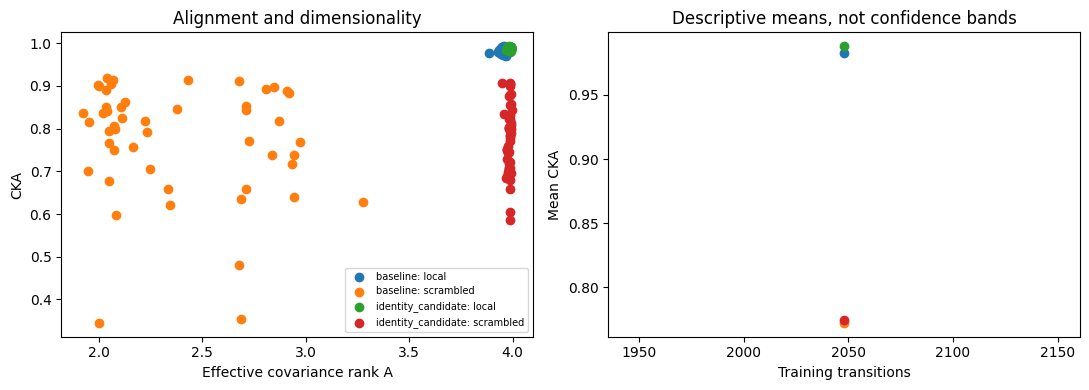

In [29]:
if bundle is not None:
    contrasts = paired_contrasts(results, metric='cka', group_by=['regime', 'n_pairs', 'step'])
    display(contrasts)
    last = results[results.step == FIT.steps]
    display(last[['regime', 'condition', 'world', 'repeat', 'eigenvalues_a', 'eigenvalues_b',
                  'state_mean_variance_corrected_a', 'within_state_noise_variance_a',
                  'state_mean_variance_corrected_b', 'within_state_noise_variance_b', 'any_collapse']])
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for (regime, condition), block in last.groupby(['regime', 'condition']):
        axes[0].scatter(block.effective_rank_a, block.cka, label=f'{regime}: {condition}')
        axes[1].plot(block.groupby('n_pairs').cka.mean(), 'o-', label=f'{regime}: {condition}')
    axes[0].set(xlabel='Effective covariance rank A', ylabel='CKA', title='Alignment and dimensionality')
    axes[1].set(xlabel='Training transitions', ylabel='Mean CKA', title='Descriptive means, not confidence bands')
    axes[0].legend(fontsize=7)
    fig.tight_layout()
    plt.show()
else:
    print('No results yet. The experiment checklist and configuration above define what to run.')

## Optional export and persistence

The results, training histories, exact plan, and environment can be packaged into ZIP bytes in RAM. No archive or automatic browser download is produced on your laptop. With `SAVE_RESULTS=False`, a runtime interruption loses progress; enable saving to an explicitly chosen persistent/cloud directory before a long run if desired.

The optional download link below works only when you choose to display it and click it. It is not invoked automatically. Checkpoints written in opt-in mode can resume matching runs; source, package versions, settings, and device contribute to identity. These are new runs, not silent reuse of legacy outputs.

In [30]:
SHOW_DOWNLOAD_LINK = True
EXPORT_BYTES = bundle_zip(bundle) if bundle is not None else None
if EXPORT_BYTES is not None:
    print(f'{len(EXPORT_BYTES):,} export bytes prepared in RAM. Saving enabled: {SAVE_RESULTS}')
    if SHOW_DOWNLOAD_LINK:
        import base64
        from IPython.display import HTML
        display(HTML('<a download="alignment_collapse.zip" href="data:application/zip;base64,' +
                     base64.b64encode(EXPORT_BYTES).decode() + '">Click to download</a>'))
else:
    print('No completed training results to export. Nothing has been saved.')

779,511 export bytes prepared in RAM. Saving enabled: False
